# Hands-on 22 (Bab 9): Deteksi Anomali Arus Listrik dengan Isolation Forest

Buku Referensi: *IoT Terintegrasi dengan Machine Learning & Data Analytics* (Onno W. Purbo), Bab 9.

Isolation Forest membangun baseline perilaku normal dan menandai titik menyimpang
tanpa label. Dataset sintetis punya 15 anomali buatan dengan ground truth untuk evaluasi.

In [1]:
import os
from pathlib import Path

while not (Path.cwd() / "scripts" / "mqtt").is_dir():
    os.chdir("..")
print("[INFO] Working directory:", Path.cwd())

[INFO] Working directory: /home/sandbox/iot-ml-book


## 1. Generate Dataset Arus + Anomali

In [2]:
import subprocess, sys
r = subprocess.run([sys.executable, "scripts/generate_current_anomaly_dataset.py"], capture_output=True, text=True)
print(r.stdout)

[SUKSES] Dataset arus listrik disimpan ke: data/synthetic/current_sensor_anomaly.csv
          timestamp device_id  current_amp  voltage  power_watt  ground_truth_anomaly
2026-01-01 00:00:00   meter01        6.152   224.09     1378.69                     0
2026-01-01 00:10:00   meter01        5.480   222.69     1220.32                     0
2026-01-01 00:20:00   meter01        6.375   217.84     1388.79                     0
2026-01-01 00:30:00   meter01        6.470   215.49     1394.30                     0
2026-01-01 00:40:00   meter01        5.024   211.11     1060.70                     0
Jumlah anomali buatan: 15



## 2. Isolation Forest

=== Hasil Isolation Forest ===
iforest_anomaly
0    485
1     15

[SUKSES] outputs/reports/current_iforest_results.csv
[SUKSES] outputs/figures/current_iforest_anomaly.png



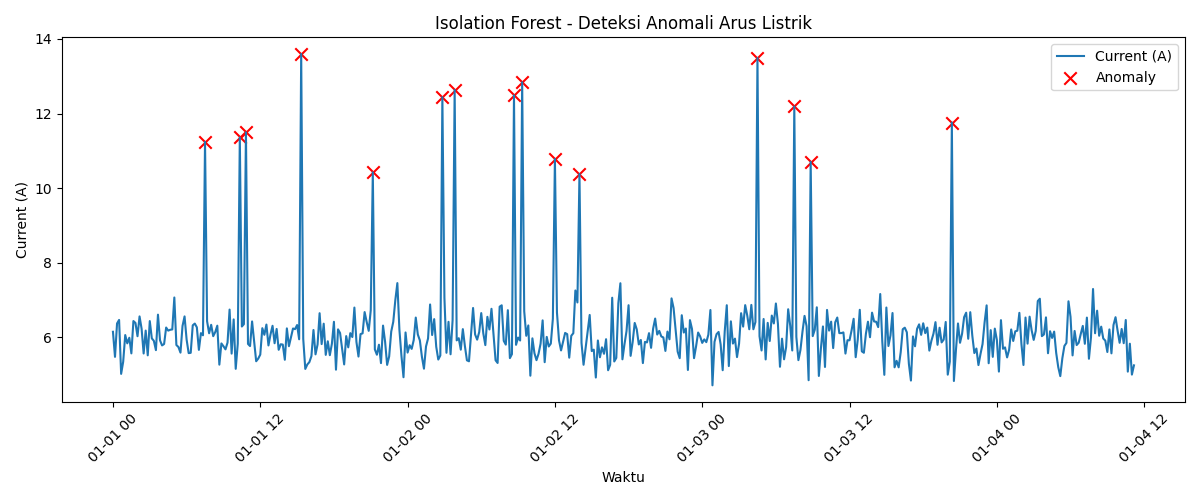

In [3]:
r = subprocess.run([sys.executable, "scripts/isolation_forest_current.py"], capture_output=True, text=True)
print(r.stdout)
from IPython.display import Image
Image("outputs/figures/current_iforest_anomaly.png")

## 3. Evaluasi terhadap Ground Truth

In [4]:
r = subprocess.run([sys.executable, "scripts/evaluate_iforest_current.py"], capture_output=True, text=True)
print(r.stdout)

=== Confusion Matrix (baris: ground truth, kolom: prediksi) ===
[[485   0]
 [  0  15]]

=== Classification Report ===
              precision    recall  f1-score   support

      normal       1.00      1.00      1.00       485
     anomaly       1.00      1.00      1.00        15

    accuracy                           1.00       500
   macro avg       1.00      1.00      1.00       500
weighted avg       1.00      1.00      1.00       500




## Penutup

Dengan contamination=0.03 (15 dari 500 titik), Isolation Forest menandai persis 15
anomali buatan: precision, recall, dan F1 = 1.00 untuk kelas anomaly. Ini kasus ideal
karena lonjakan 4-8 A sangat jauh dari baseline (6.0 +/- 0.5 A); pada data nyata,
contamination perlu disetel dan hasil diverifikasi manual. Hasil tersimpan di
`outputs/reports/current_iforest_results.csv`.